# (DSC555) Model Evaluation
Author: Tracey Johnson/
Date: 10-21-2026/
Python version 3.13

This notebook focuses on the evaluation and refinement of machine learning models developed for the access barriers analysis project. Notice narrative that explains revisions, improvements, and the rationale behind dataset selection and model adjustments. It will cover performance metrics, error analysis, hyperparameter tuning, and model comparison to ensure the most effective model is selected for deployment.

1. Dataset Selection and Preparation (revised)
2. Evaluate Model Performance
3. Report Findings
4. References

README: https://github.com/tdjohnson3210-oss/access-barriers-analysis/blob/main/README.md

In [1]:
import pandas as pd
import requests
import io
import os
import joblib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully.")

Libraries imported successfully.


---

## Dataset Selection and Preparation (revised)

### Primary Dataset

This experiment will continue to use the **American Community Survey (ACS)** estimates with **Rural–Urban Commuting Area (RUCA)** classifications at the census tract level. The ACS data provide detailed demographic, economic, housing, internet access, and commuting characteristics, while the RUCA codes offer insights into the rurality and urbanization of each tract. By combining these datasets, the analysis can account for both socioeconomic conditions and geographic context, which is crucial for understanding access barriers in civil court utilization. Exploratory analysis was previously conducted to identify patterns and relationships within the data, guiding the subsequent steps of model evaluation and refinement.

In [2]:
base_url = (
    "https://raw.githubusercontent.com/"
    "tdjohnson3210-oss/access-barriers-analysis/main/data_processed"
)

dfs = []

for i in range(9):
    file_url = f"{base_url}/df_primary_part_{i}.parquet"
    dfs.append(pd.read_parquet(file_url))

df_primary = pd.concat(
    dfs,
    ignore_index=True
)

print(df_primary.shape)

(426949, 72)


In [3]:
print("First 5 rows of the dataset:")
(df_primary.head())

First 5 rows of the dataset:


,geography,households_by_type_total_households_married_couple_family,households_by_type_total_households_cohabiting_couple_household,households_by_type_total_households_male_householder_no_spouse/partner_present,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_female_householder_no_spouse/partner_present,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_households_with_one_or_more_people_under_18_years,...,primaryruca,primaryrucadescription,secondaryruca,secondaryrucadescription,population,landarea,popdensity,transportation_households_no_vehicle,transportation_households_one_vehicle,transportation_households_high_vehicle_access
0,1400000US01001020100,433.0,9.0,99.0,71.0,44.0,152.0,58.0,25.0,217.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",1775.0,3.8,467.9,10.0,181.0,259.0
1,1400000US01001020200,202.0,36.0,142.0,92.0,16.0,193.0,99.0,64.0,170.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",2055.0,1.3,1602.7,57.0,226.0,91.0
2,1400000US01001020300,657.0,165.0,203.0,152.0,28.0,326.0,154.0,102.0,583.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",3216.0,2.1,1557.1,42.0,443.0,475.0
3,1400000US01001020400,967.0,40.0,264.0,141.0,41.0,365.0,271.0,132.0,321.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",4246.0,2.5,1722.5,72.0,590.0,313.0
4,1400000US01001020501,1043.0,0.0,211.0,135.0,41.0,452.0,293.0,83.0,555.0,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",4322.0,2.4,1804.4,44.0,485.0,363.0


In [4]:
print("Last 5 rows of the dataset:")
(df_primary.tail())

Last 5 rows of the dataset:


,geography,households_by_type_total_households_married_couple_family,households_by_type_total_households_cohabiting_couple_household,households_by_type_total_households_male_householder_no_spouse/partner_present,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_female_householder_no_spouse/partner_present,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,households_by_type_total_households_households_with_one_or_more_people_under_18_years,...,primaryruca,primaryrucadescription,secondaryruca,secondaryrucadescription,population,landarea,popdensity,transportation_households_no_vehicle,transportation_households_one_vehicle,transportation_households_high_vehicle_access
426944,1400000US72153750501,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",3968.0,0.7,5646.2,160.0,779.0,278.0
426945,1400000US72153750502,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",1845.0,0.3,6926.1,110.0,394.0,106.0
426946,1400000US72153750503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",2155.0,1.3,1692.1,47.0,257.0,158.0
426947,1400000US72153750601,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",4368.0,4.2,1029.9,117.0,550.0,389.0
426948,1400000US72153750602,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,Metropolitan core,1,"Metropolitan core, no addtional code",2587.0,6.8,382.4,154.0,392.0,49.0


Check for duplicate and missing values in the dataset.

In [5]:
print("Number of duplicate rows:", df_primary.duplicated().sum())

Number of duplicate rows: 0


In [6]:
print("Count of duplicated rows based on 'geography' and 'year':", df_primary.duplicated(["geography", "year"]).sum())

Count of duplicated rows based on 'geography' and 'year': 0


In [7]:
print("Count of columns with any missing values:", (df_primary.isnull().sum() > 0).sum())
primary_missing = (df_primary.isnull().sum() / len(df_primary) * 100)
(
    primary_missing[primary_missing > 0]
    .sort_values(ascending=False)
)

Count of columns with any missing values: 65


households_by_type_total_households_average_family_size                            2.455563
households_by_type_total_households_average_household_size                         2.429564
households_by_type_total_households_married_couple_family                          1.148849
language_spoken_at_home_population_5_years_and_over_language_other_than_english    1.148849
residence_1_year_ago_population_1_year_and_over                                    1.148849
                                                                                     ...   
countyname20                                                                       0.621151
countycode20                                                                       0.621151
statename20                                                                        0.621151
statefips20                                                                        0.621151
popdensity                                                                      

Check data types.

In [8]:
print("Data types of each column:")
(df_primary.dtypes)

Data types of each column:


geography                                                                                                   object
households_by_type_total_households_married_couple_family                                                  float64
households_by_type_total_households_cohabiting_couple_household                                            float64
households_by_type_total_households_male_householder_no_spouse/partner_present                             float64
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone    float64
                                                                                                            ...   
landarea                                                                                                   float64
popdensity                                                                                                 float64
transportation_households_no_vehicle                                            

Categorize barrier columns and create separate dfs for each category.

In [9]:
df_primary.columns.tolist()

['geography',
 'households_by_type_total_households_married_couple_family',
 'households_by_type_total_households_cohabiting_couple_household',
 'households_by_type_total_households_male_householder_no_spouse/partner_present',
 'households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone',
 'households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over',
 'households_by_type_total_households_female_householder_no_spouse/partner_present',
 'households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone',
 'households_by_type_total_households_female_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over',
 'households_by_type_total_households_households_with_one_or_more_people_under_18_years',
 'households_by_type_total_households_households_with_one_or_more_people_65_years_and_over',
 'households_by_type_total_househ

In [10]:
# Geographic identifiers
geo_cols = [
    'geography',
    'year',
    'tract_name',
    'geoid',
    'statefips20',
    'statename20',
    'countyfips20',
    'countycode20',
    'countyname20'
]

# Household / Family Barriers
household_cols = [
    c for c in df_primary.columns
    if c.startswith('households_by_type_')
]

# Education Barriers
education_cols = [
    c for c in df_primary.columns
    if c.startswith('educational_attainment_')
]

# Disability Barriers
disability_cols = [
    c for c in df_primary.columns
    if c.startswith(
        'disability_status_of_the_civilian_noninstitutionalized_population'
    )
]

# Mobility / Residential Stability Barriers
mobility_cols = [
    c for c in df_primary.columns
    if c.startswith('residence_1_year_ago_')
]

# Language Barriers
language_cols = [
    c for c in df_primary.columns
    if c.startswith('language_spoken_at_home_')
]

# Digital Access Barriers
digital_cols = [
    c for c in df_primary.columns
    if c.startswith('computers_and_internet_use_')
]

# Transportation Barriers
transportation_cols = [
    'transportation_households_no_vehicle',
    'transportation_households_one_vehicle',
    'transportation_households_high_vehicle_access'
]

# Geographic Access / Rurality Barriers (numeric only)
rurality_cols = [
    'urbancore',
    'primaryruca',
    'secondaryruca',
    'population',
    'landarea',
    'popdensity'
]

# All barrier categories
barrier_categories = {
    "household": household_cols,
    "education": education_cols,
    "disability": disability_cols,
    "mobility": mobility_cols,
    "language": language_cols,
    "digital": digital_cols,
    "transportation": transportation_cols,
    "rurality": rurality_cols
}

# All model variables
all_barrier_vars = (
    household_cols +
    education_cols +
    disability_cols +
    mobility_cols +
    language_cols +
    digital_cols +
    transportation_cols +
    rurality_cols
)

In [11]:
for category, cols in barrier_categories.items():
    print(f"{category}: {len(cols)} columns")

household: 12 columns
education: 10 columns
disability: 7 columns
mobility: 8 columns
language: 12 columns
digital: 2 columns
transportation: 3 columns
rurality: 6 columns


---

### Secondary Dataset Overview

The National Center for State Courts (NCSC) Court Statistics Project (CSP) dataset presented an agggregation issue, as it provides data at the state-year level rather than at the county or tract level. This limitation affects the granularity of the analysis, making it challenging to directly align the CSP data with the more detailed ACS and RUCA datasets. 

Washington County’s superior court data will serve as the pilot site because the information is readily accessible and ready for analysis. Purposeful sampling principles emphasize selecting cases based on availability and willingness to participate  and using convenience or opportunistic sampling when researchers take advantage of accessible data sources (Palinkas et al., 2015). Using Washington County allows the project to align court records more closely with ACS and RUCA datasets, supporting a more detailed examination of access‑to‑justice patterns at the local level.

In [12]:
url = "https://raw.githubusercontent.com/tdjohnson3210-oss/access-barriers-analysis/main/data_raw"

In [13]:
files = {
    2021: "wa_filings_2021.xlsx",
    2022: "wa_filings_2022.xlsx",
    2023: "wa_filings_2023.xlsx",
    2024: "wa_filings_2024.xlsx"
}

dfs = []

for year, file in files.items():
    df = pd.read_excel(f"{url}/{file}")
    df["year"] = year
    dfs.append(df)

In [14]:
df_secondary = (
    pd.concat(dfs, ignore_index=True)
    .loc[
        lambda x: (
            x["Court Name"].str.strip().str.lower() != "total"
        ) & (
            x["Court County Name"].str.strip().str.lower() != "total"
        )
    ]
)

print(f"Observations: {len(df_secondary)}")
print(f"Unique counties: {df_secondary['Court County Name'].nunique()}")

Observations: 156
Unique counties: 39


View historical data.

In [15]:
print("First 5 rows of secondary data")
print(df_secondary.head())

First 5 rows of secondary data
  Court County Name                      Court Name  (1) Criminal  (2) Civil  \
0             Adams     ADAMS COUNTY SUPERIOR COURT           125         95   
1            Asotin    ASOTIN COUNTY SUPERIOR COURT           128        222   
2          Columbia  COLUMBIA COUNTY SUPERIOR COURT            23         64   
3          Garfield  GARFIELD COUNTY SUPERIOR COURT            16         16   
4            Benton    BENTON COUNTY SUPERIOR COURT          1210       1715   

   Domestic  (5) Probate, Guardianship  (3) Adoption, Parentage  \
0        50                         68                       18   
1       152                        103                       15   
2        14                         33                        2   
3        14                         11                        5   
4       873                        767                      129   

   Mental Illness  (4) Juvenile Dependency  (1) Juvenile Offender  Total  year  
0   

In [16]:
print("Last 5 rows of secondary data")
print(df_secondary.tail())

Last 5 rows of secondary data
    Court County Name                         Court Name  (1) Criminal  \
154          Thurston     THURSTON COUNTY SUPERIOR COURT          1610   
155       Walla Walla  WALLA WALLA COUNTY SUPERIOR COURT           382   
156           Whatcom      WHATCOM COUNTY SUPERIOR COURT          1486   
157           Whitman      WHITMAN COUNTY SUPERIOR COURT           200   
158            Yakima       YAKIMA COUNTY SUPERIOR COURT          1909   

     (2) Civil  Domestic  (5) Probate, Guardianship  (3) Adoption, Parentage  \
154       5608      1378                       1151                      179   
155        883       262                        294                       35   
156       2284       748                       1165                      155   
157        385       102                        160                       17   
158       3838       922                        940                      249   

     Mental Illness  (4) Juvenile Dependency

Identify any duplicate or missing values in the dataset.

In [17]:
print("Number of duplicate rows:", df_secondary.duplicated().sum())

Number of duplicate rows: 0


In [18]:
print("Count of columns with any missing values:", (df_secondary.isnull().sum() > 0).sum())

Count of columns with any missing values: 0


Check data types.

In [19]:
print(df_secondary.dtypes)

Court County Name            object
Court Name                   object
(1) Criminal                  int64
(2) Civil                     int64
Domestic                      int64
(5) Probate, Guardianship     int64
(3) Adoption, Parentage       int64
Mental Illness                int64
(4) Juvenile Dependency       int64
(1) Juvenile Offender         int64
Total                         int64
year                          int64
dtype: object


In [20]:
df_secondary.columns = (
    df_secondary.columns
    .str.lower()
    .str.strip()
    .str.replace(r"\(\d+\)", "", regex=True)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

print(df_secondary.columns.tolist())

['court_county_name', 'court_name', 'criminal', 'civil', 'domestic', 'probate_guardianship', 'adoption_parentage', 'mental_illness', 'juvenile_dependency', 'juvenile_offender', 'total', 'year']


Also, standardize `court_name' values.

In [21]:
df_secondary["court_name"] = (
    df_secondary["court_name"]
    .str.strip()
    .str.title()
)

Remove columns not relevant to civil cases.

In [22]:
cols_to_keep = (
    df_secondary.select_dtypes(include="object").columns.tolist()
    + ["year", "civil", "total"]
)

df_secondary = df_secondary[cols_to_keep]

print(df_secondary.columns)

Index(['court_county_name', 'court_name', 'year', 'civil', 'total'], dtype='object')


#### Descriptive Statistics

Univariate analysis.

In [23]:
print("Descriptive Statistics for All Columns")
print(df_secondary.describe(include="all"))

Descriptive Statistics for All Columns
       court_county_name                   court_name         year  \
count                156                          156   156.000000   
unique                39                           39          NaN   
top                Adams  Adams County Superior Court          NaN   
freq                   4                            4          NaN   
mean                 NaN                          NaN  2022.500000   
std                  NaN                          NaN     1.121635   
min                  NaN                          NaN  2021.000000   
25%                  NaN                          NaN  2021.750000   
50%                  NaN                          NaN  2022.500000   
75%                  NaN                          NaN  2023.250000   
max                  NaN                          NaN  2024.000000   

               civil         total  
count     156.000000    156.000000  
unique           NaN           NaN  
top      

Observations:

- The dataset contains 156 county-year observations representing 39 Washington counties observed annually from 2021 to 2024.
- Each county contributed four observations, creating a balanced panel structure suitable for longitudinal analysis.
- Civil filings averaged 2,183.52 cases per county-year observation, with a median of 689.50 cases.
- Total filings averaged 5,591.48 cases per county-year observation, with a median of 2,117.50 cases.
- Civil filings varied considerably across counties and years, ranging from 15 to 29,445 cases.
- Total filings ranged from 58 to 59,647 cases, indicating substantial differences in court activity across jurisdictions.
- The mean exceeded the median for both civil and total filings, suggesting a right-skewed distribution driven by a small number of high-volume counties.
- The presence of both geographic (39 counties) and temporal (4 years) variation supports the use of regression and machine learning models to examine factors associated with civil filing activity.

Visualizations.

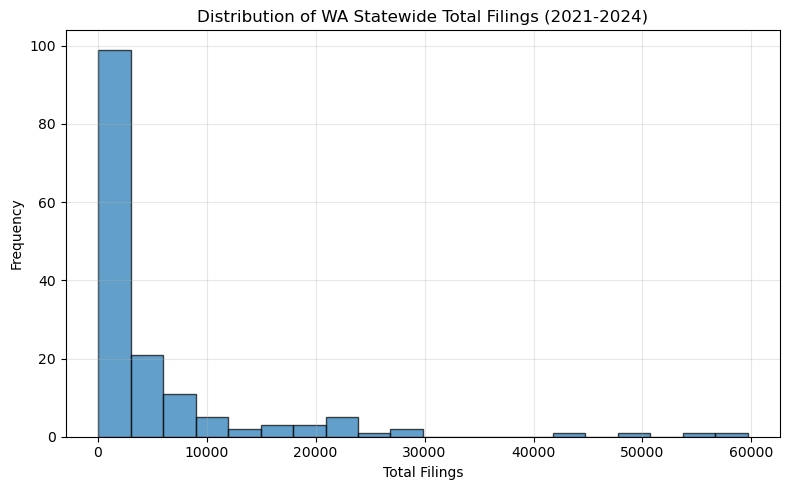

In [24]:
# histogram of numerical filings
plt.figure(figsize=(8, 5))
plt.hist(df_secondary["total"], bins=20, edgecolor="k", alpha=0.7)
plt.title("Distribution of WA Statewide Total Filings (2021-2024)")
plt.xlabel("Total Filings")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

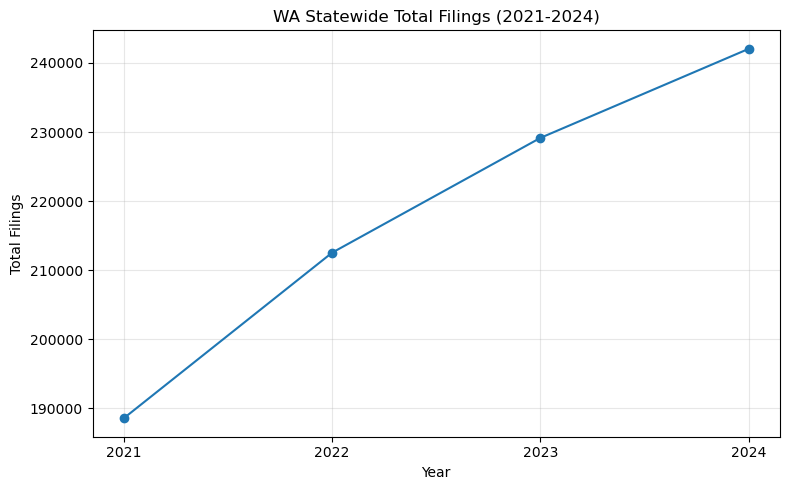

In [25]:
statewide_total = (
    df_secondary.groupby("year")["total"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8, 5))
plt.plot(statewide_total["year"], statewide_total["total"], marker="o")
plt.xticks(statewide_total["year"])

plt.title("WA Statewide Total Filings (2021-2024)")
plt.xlabel("Year")
plt.ylabel("Total Filings")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Observations:

WA statewide total filings increased steadily from 2021 to 2024, supporting national patterns of rising civil court activity described by the Court Statistics Project’s early‑2025 signals report (Court Statistics Project, 2026).

In [26]:
# Save final seconary dataset as parquet
df_secondary.to_parquet("df_secondary.parquet", index=False)

---

## Evaluate Model Performance

Before modeling, the revised secondary dataset must be merged with the primary dataset to ensure that all relevant features are included in the analysis. This process will involve identifying and matching common keys to facilitate an accurate merge between the two datasets. 

In [27]:
primary = set(
    df_primary['countyname20']
    .str.lower()
    .str.replace(' county', '', regex=False)
)

secondary = set(
    df_secondary['court_county_name']
    .str.lower()
)

print(primary == secondary)

False


Since the county names were standardized and all 39 Washington counties matched between datasets, Washington was filtered as the pilot state and the model dataframe can now be constructed using the matched records.

In [28]:
model_df = df_primary[
    (df_primary['statename20'] == 'Washington') &
    (df_primary['year'] != 2020)
][
    geo_cols + all_barrier_vars
].copy()

model_df.shape

(7136, 69)

In [29]:
# Create county key
model_df['county_clean'] = (
    model_df['countyname20']
    .str.lower()
    .str.replace(' county', '', regex=False)
)

df_secondary['county_clean'] = (
    df_secondary['court_county_name']
    .str.lower()
)

In [30]:
# Merge civil filings
model_df = model_df.merge(
    df_secondary[['county_clean', 'year', 'civil']],
    on=['county_clean', 'year'],
    how='left'
)

model_df.shape

(7136, 71)

In [31]:
# Create barrier dataset
df_barriers = model_df[all_barrier_vars].copy()
df_barriers.shape

(7136, 60)

Variables were standardized using z-scores to place all measures on a common scale. This ensured that variables with larger values did not disproportionately influence barrier scores and allowed meaningful comparisons across barrier categories.

In [32]:
# Standardize
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

z_df = pd.DataFrame(
    scaler.fit_transform(df_barriers),
    columns=[f'z_{c}' for c in df_barriers.columns],
    index=model_df.index
)

In [33]:
# Attach z-scores
model_df = pd.concat([model_df, z_df], axis=1)
model_df.shape

(7136, 131)

In [34]:
# Select relevant columns
score_groups = {
    'transportation': transportation_cols,
    'digital': digital_cols,
    'education': education_cols,
    'language': language_cols,
    'disability': disability_cols,
    'household': household_cols,
    'mobility': mobility_cols
}

for name, cols in score_groups.items():
    z_cols = [f'z_{c}' for c in cols]
    model_df[f'{name}_score'] = model_df[z_cols].mean(axis=1)

In [35]:
model_df = model_df[
    [
        'geoid',
        'year',
        'countyname20',
        'population',
        'popdensity',
        'primaryruca'
    ] +
    [c for c in model_df.columns if c.endswith('_score')] +
    [c for c in model_df.columns if 'civil' in c.lower()]
].copy()

print(model_df.columns.tolist())
print(model_df.shape)

['geoid', 'year', 'countyname20', 'population', 'popdensity', 'primaryruca', 'transportation_score', 'digital_score', 'education_score', 'language_score', 'disability_score', 'household_score', 'mobility_score', 'disability_status_of_the_civilian_noninstitutionalized_population_total_civilian_noninstitutionalized_population_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_under_18_years', 'disability_status_of_the_civilian_noninstitutionalized_population_under_18_years_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years', 'disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over', 'disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over_with_a_disability', 'civil', 'z_disability_status_of_the_civilian_noninstitutionalized_population_total_civili

In [36]:
# Recreate merge keys
model_df['county_clean'] = (
    model_df['countyname20']
    .str.lower()
    .str.replace(' county', '', regex=False)
)

df_secondary['county_clean'] = (
    df_secondary['court_county_name']
    .str.lower()
)

# Re-merge civil filings
model_df = model_df.merge(
    df_secondary[['county_clean', 'year', 'civil']],
    on=['county_clean', 'year'],
    how='left'
)

# Remove helper column if desired
model_df = model_df.drop(columns=['county_clean'])

print(model_df.columns.tolist())

['geoid', 'year', 'countyname20', 'population', 'popdensity', 'primaryruca', 'transportation_score', 'digital_score', 'education_score', 'language_score', 'disability_score', 'household_score', 'mobility_score', 'disability_status_of_the_civilian_noninstitutionalized_population_total_civilian_noninstitutionalized_population_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_under_18_years', 'disability_status_of_the_civilian_noninstitutionalized_population_under_18_years_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years', 'disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over', 'disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over_with_a_disability', 'civil_x', 'z_disability_status_of_the_civilian_noninstitutionalized_population_total_civi

In [37]:
print(model_df.describe())

              year   population     popdensity  primaryruca  \
count  7136.000000   7136.00000    7136.000000  7136.000000   
mean   2022.500000   4319.10370    4226.443946     2.743834   
std       1.118112   1507.78524    6841.396917     8.277254   
min    2021.000000      0.00000       0.000000     1.000000   
25%    2021.750000   3320.75000     513.850000     1.000000   
50%    2022.500000   4218.00000    2912.700000     1.000000   
75%    2023.250000   5358.25000    5348.025000     2.000000   
max    2024.000000  10570.00000  124339.300000    99.000000   

       transportation_score  digital_score  education_score  language_score  \
count          7.136000e+03   7.136000e+03      7136.000000    7.136000e+03   
mean          -2.389718e-17  -1.075373e-16         0.000000   -5.974294e-18   
std            5.744811e-01   9.988449e-01         0.616000    5.845971e-01   
min           -1.298833e+00  -2.717954e+00        -1.727831   -1.038862e+00   
25%           -3.852834e-01  -6.66273

Remove tracts coded as 99 because these represent "Not coded" or water-only areas, not valid RUCA classifications. Including them would incorrectly treat 99 as a meaningful rurality value in the model.

In [38]:
model_df = model_df[
    model_df['primaryruca'] != 99
].copy()

print(model_df['primaryruca'].value_counts().sort_index())
print(f"Rows remaining: {len(model_df):,}")

primaryruca
1.0     5012
2.0      916
3.0       28
4.0      380
5.0      128
6.0       20
7.0      116
8.0       36
10.0     452
Name: count, dtype: int64
Rows remaining: 7,088


In [39]:
(model_df['civil_x'] == model_df['civil_y']).all()
model_df = (
    model_df
    .drop(columns=['civil_y'])
    .rename(columns={'civil_x': 'civil'})
)

In [40]:
print('civil' in model_df.columns)
print(model_df.columns.tolist())


True
['geoid', 'year', 'countyname20', 'population', 'popdensity', 'primaryruca', 'transportation_score', 'digital_score', 'education_score', 'language_score', 'disability_score', 'household_score', 'mobility_score', 'disability_status_of_the_civilian_noninstitutionalized_population_total_civilian_noninstitutionalized_population_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_under_18_years', 'disability_status_of_the_civilian_noninstitutionalized_population_under_18_years_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years', 'disability_status_of_the_civilian_noninstitutionalized_population_18_to_64_years_with_a_disability', 'disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over', 'disability_status_of_the_civilian_noninstitutionalized_population_65_years_and_over_with_a_disability', 'civil', 'z_disability_status_of_the_civilian_noninstitutionalized_population_total_c

In [41]:
cols_to_drop = [
    c for c in model_df.columns
    if c.startswith('disability_status_')
    or c.startswith('z_disability_status_')
]

model_df = model_df.drop(columns=cols_to_drop)

print(model_df.columns.tolist())

['geoid', 'year', 'countyname20', 'population', 'popdensity', 'primaryruca', 'transportation_score', 'digital_score', 'education_score', 'language_score', 'disability_score', 'household_score', 'mobility_score', 'civil']


---

#### Model 1: Which Access Barriers Are Associated with Civil Filings?

To better understand how access barriers are associated with civil filings, an initial regression model will be developed using the barrier category scores created during preprocessing. Civil filings will serve as the target variable, while transportation, digital, education, language, disability, household, and mobility barrier scores will be predictors. 

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [43]:
# list all columns in the model dataframe
print(model_df.columns.tolist())

['geoid', 'year', 'countyname20', 'population', 'popdensity', 'primaryruca', 'transportation_score', 'digital_score', 'education_score', 'language_score', 'disability_score', 'household_score', 'mobility_score', 'civil']


In [44]:
model_df = (
    model_df
    .groupby(['countyname20', 'year'], as_index=False)
    .agg({
        'civil': 'first',
        'population': 'sum',
        'popdensity': 'mean',
        'primaryruca': 'mean',
        'transportation_score': 'mean',
        'digital_score': 'mean',
        'education_score': 'mean',
        'language_score': 'mean',
        'disability_score': 'mean',
        'household_score': 'mean',
        'mobility_score': 'mean'
    })
)

# keep original values for dashboard

model_df["population_actual"] = model_df["population"]

model_df["popdensity_actual"] = model_df["popdensity"]

model_df["primaryruca_actual"] = model_df["primaryruca"]

In [45]:
from sklearn.preprocessing import StandardScaler

predictor_cols = [
    'transportation_score',
    'digital_score',
    'education_score',
    'language_score',
    'disability_score',
    'household_score',
    'mobility_score',
    'population',
    'popdensity',
    'primaryruca'
]

# Preserve original display values
model_df["population_actual"] = model_df["population"]
model_df["popdensity_actual"] = model_df["popdensity"]
model_df["primaryruca_actual"] = model_df["primaryruca"]

scaler = StandardScaler()

model_df[predictor_cols] = scaler.fit_transform(
    model_df[predictor_cols]
)

In [46]:
print(model_df.shape)
print(model_df['year'].nunique())
print(model_df['countyname20'].nunique())

(156, 16)
4
39


In [47]:
y = model_df['civil']

X = model_df[
    [
        'transportation_score',
        'digital_score',
        'education_score',
        'language_score',
        'disability_score',
        'household_score',
        'mobility_score',
        'population',
        'popdensity',
        'primaryruca'
    ]
]

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [49]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [50]:
# Save model
joblib.dump(model, "civil_filings_model.pkl")

# Save feature names
joblib.dump(X.columns.tolist(), "civil_filings_features.pkl")

print("Civil filings model saved.")

Civil filings model saved.


Generate predictions.

In [51]:
y_pred = model.predict(X_test)

In [52]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("R²:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R²: 0.8946027550027242
MAE: 371.1349286223731
RMSE: 562.2573009374737


In [53]:
coef_df = pd.DataFrame({
    'Barrier': X.columns,
    'Coefficient': model.coef_
})

coef_df['Absolute_Impact'] = abs(coef_df['Coefficient'])

coef_df = coef_df.sort_values(
    'Absolute_Impact',
    ascending=False
)

print(coef_df)

                Barrier  Coefficient  Absolute_Impact
7            population  4621.648970      4621.648970
8            popdensity  -752.625607       752.625607
2       education_score  -489.432858       489.432858
1         digital_score   488.278654       488.278654
9           primaryruca  -484.958256       484.958256
4      disability_score   218.188314       218.188314
0  transportation_score  -140.889152       140.889152
3        language_score   115.140480       115.140480
5       household_score    71.673192        71.673192
6        mobility_score   -70.578925        70.578925


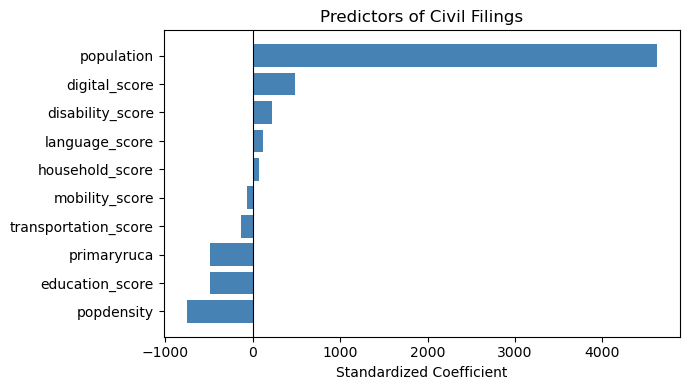

In [54]:
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient': model.coef_
})

coef_df = coef_df.sort_values('Coefficient')

plt.figure(figsize=(7, 4))
plt.barh(
    coef_df['Variable'],
    coef_df['Coefficient'],
    color='steelblue'
)

plt.axvline(0, color='black', linewidth=0.8)
plt.title('Predictors of Civil Filings')
plt.xlabel('Standardized Coefficient')
plt.ylabel('')

plt.tight_layout()
plt.show()

To better align the geographic scale of the predictors and outcome, tract-level barrier scores were aggregated to the county-year level and combined with county-level civil filing data. Population, population density, and rurality were also included as control variables. The resulting model explained 89.5% of the variation in civil filings (R² = 0.895) and achieved a mean absolute error of 371 filings and a root mean squared error of 562 filings, indicating strong overall model performance.

After accounting for population, population density, rurality, and other barrier categories, transportation barriers showed a small negative association with civil filings. This suggests that counties with higher transportation barriers tended to have slightly fewer civil filings than would otherwise be expected based on the other factors included in the model.

### Additional Model Validation

After evaluating model performance with R², MAE, and RMSE, an OLS regression is used to determine which predictors are statistically significant and how each variable is associated with civil filings. While performance metrics show how well the model predicts outcomes, OLS helps identify whether transportation barriers remain meaningful after controlling for population, population density, rurality, and other access barriers.

In [55]:
import statsmodels.api as sm

In [56]:
# Add intercept
X_ols = sm.add_constant(X)

# Fit OLS regression
ols_model = sm.OLS(y, X_ols).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  civil   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.942
Method:                 Least Squares   F-statistic:                     251.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           3.00e-86
Time:                        19:07:39   Log-Likelihood:                -1299.9
No. Observations:                 156   AIC:                             2622.
Df Residuals:                     145   BIC:                             2655.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 2183.5192 

### Performance Analysis

This visualization compares the model's predicted civil filings to the observed civil filings in the testing dataset. Most observations fall close to the 1:1 reference line, indicating that the model generally predicted filing activity accurately and supporting the strong model performance (R² = 0.945). But, a small number of observations deviated from the line, suggesting that some county-year filing patterns may be influenced by factors not included in the model.

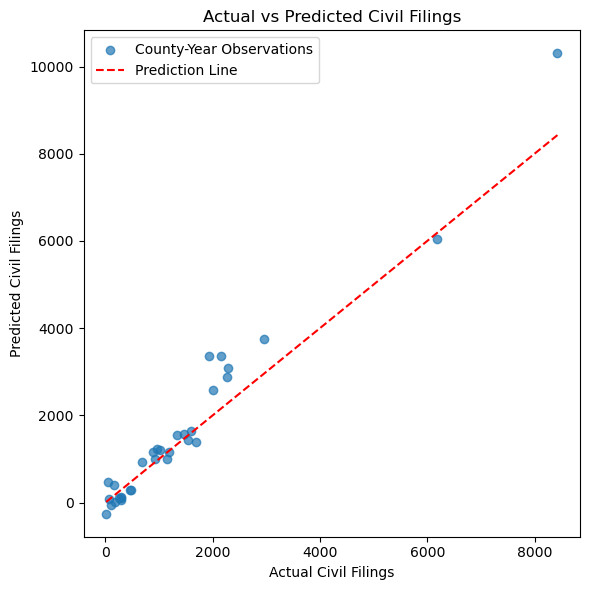

In [57]:
plt.figure(figsize=(6,6))
plt.scatter(
    y_test,
    y_pred,
    alpha=0.7,
    label='County-Year Observations'
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Prediction Line'
)

plt.xlabel('Actual Civil Filings')
plt.ylabel('Predicted Civil Filings')
plt.title('Actual vs Predicted Civil Filings')

plt.legend()
plt.tight_layout()
plt.show()

### Model Refinement 

Model was refined earlier to improve model validity and interpretability. Specifically, tract-level barrier measures were aggregated to the county-year level to align with county-level civil filing data, and population, population density, and rurality were added as control variables. 

Predictor variables were also standardized, and multicollinearity and statistical significance testing were conducted to evaluate model assumptions and improve interpretation of the results.

### Save data for dashboard

In [58]:
model_df["predicted_civil_filings"] = (
    model.predict(
        model_df[predictor_cols]
    )
)

model_df["filing_difference"] = (
    model_df["civil"]
    - model_df["predicted_civil_filings"]
)

In [59]:
dashboard_df = model_df.copy()

dashboard_df = dashboard_df.rename(
    columns={
        "countyname20": "county",
        "civil": "actual_civil_filings"
    }
)

dashboard_df["civil_rank"] = (
    dashboard_df
    .groupby("year")["actual_civil_filings"]
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
)

---

#### Model 2: Where Are Transportation Barriers Highest?

This model classifies county-year observations into transportation risk groups based on transportation barrier scores. The objective is to identify the factors most strongly associated with elevated transportation risk and examine how transportation barriers overlap with other access-related challenges. By using digital, educational, language, disability, household, and mobility barriers as predictors, the model helps identify patterns of disadvantage associated with transportation risk across counties over time.

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [61]:
model_df_2 = model_df.copy()

model_df_2['transportation_risk'] = pd.qcut(
    model_df_2['transportation_score'],
    q=5,
    labels=[
        'Very Low',
        'Low',
        'Moderate',
        'High',
        'Very High'
    ]
)

In [62]:
print(model_df_2['transportation_risk'].value_counts())

transportation_risk
Very Low     32
Low          31
Moderate     31
High         31
Very High    31
Name: count, dtype: int64


In [63]:
X = model_df_2[
    [
        'digital_score',
        'education_score',
        'language_score',
        'disability_score',
        'household_score',
        'mobility_score'
    ]
]

y = model_df_2['transportation_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [64]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [65]:
joblib.dump(rf, "transportation_risk_model.pkl")
joblib.dump(X.columns.tolist(), "transportation_risk_features.pkl")
print("Transportation risk model saved.")

Transportation risk model saved.


Generate predictions.

In [66]:
y_pred = rf.predict(X_test)

In [67]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.75
              precision    recall  f1-score   support

        High       0.50      0.50      0.50         6
         Low       0.83      0.83      0.83         6
    Moderate       0.75      0.86      0.80         7
   Very High       0.80      0.67      0.73         6
    Very Low       0.86      0.86      0.86         7

    accuracy                           0.75        32
   macro avg       0.75      0.74      0.74        32
weighted avg       0.75      0.75      0.75        32



In [68]:
importance_df = pd.DataFrame({
    'Barrier': X.columns,
    'Importance': rf.feature_importances_
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

print(importance_df)

            Barrier  Importance
0     digital_score    0.333626
1   education_score    0.194722
4   household_score    0.164070
5    mobility_score    0.146297
3  disability_score    0.087180
2    language_score    0.074107


Some adjustments were made to the classification model to improve interpretability and align the analysis with the county-year dataset used throughout the study. Transportation risk was categorized into five balanced risk groups ranging from Very Low to Very High, and other barrier categories were used as predictors. The resulting Random Forest model achieved an overall accuracy of 75%, indicating strong performance in identifying transportation risk levels. Feature importance results showed that digital and education barriers were the strongest predictors of transportation risk, suggesting that transportation challenges often occur alongside other forms of access disadvantage.

### Additional Model Validation

In [69]:
from sklearn.metrics import ConfusionMatrixDisplay

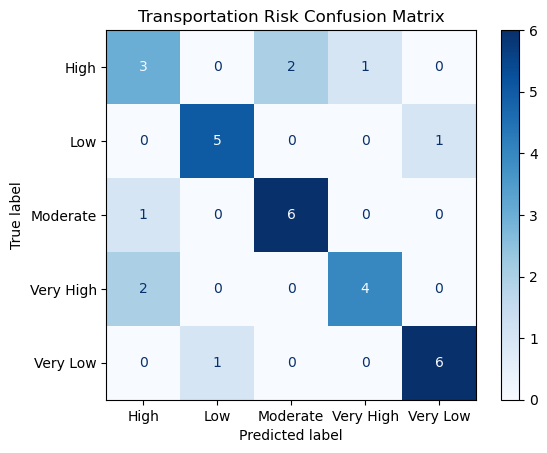

In [70]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Transportation Risk Confusion Matrix")
plt.show()

The confusion matrix shows that the model correctly classified most county-year observations into their transportation risk categories, with most errors occurring between similar risk groups rather than between substantially different levels of risk.

### Performance Analysis

This visualization examines the relative importance of each predictor in the Random Forest classification model, indicating how much each barrier category contributed to the prediction of transportation risk. The results show that digital barriers were the strongest predictor of transportation risk, followed by education, household, and mobility barriers, suggesting that transportation disadvantage is closely associated with broader access-related challenges.

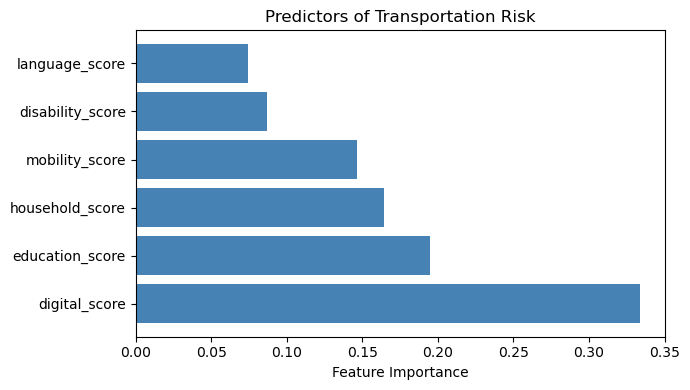

In [71]:
plt.figure(figsize=(7,4))

plt.barh(
    importance_df['Barrier'],
    importance_df['Importance'],
    color='steelblue'
)

plt.xlabel('Feature Importance')
plt.title('Predictors of Transportation Risk')

plt.tight_layout()
plt.show()

### Model Refinement

In [72]:
model_df_2_refined = model_df_2.copy()

X = model_df_2_refined[
    [
        'digital_score',
        'education_score',
        'language_score',
        'disability_score',
        'household_score',
        'mobility_score'
    ]
]

y = model_df_2_refined['transportation_risk']

In [73]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [74]:
y_pred = rf.predict(X_test)

In [75]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.75
              precision    recall  f1-score   support

        High       0.50      0.50      0.50         6
         Low       0.83      0.83      0.83         6
    Moderate       0.75      0.86      0.80         7
   Very High       0.80      0.67      0.73         6
    Very Low       0.86      0.86      0.86         7

    accuracy                           0.75        32
   macro avg       0.75      0.74      0.74        32
weighted avg       0.75      0.75      0.75        32



Hyperparameter tuning was performed to evaluate whether adjustments to the Random Forest classifier could improve transportation risk classification; however, the refined model produced results nearly identical to the original model, with no meaningful change in overall accuracy (75%).

### Save all

In [82]:
# --------------------------------------------------
# BUILD AND SAVE FINAL DASHBOARD DATASET
# Run this AFTER transportation_risk is created
# --------------------------------------------------

import pandas as pd


def classify_ruca(ruca):

    if pd.isna(ruca):
        return "Unknown"

    elif ruca <= 3:
        return "Metropolitan"

    elif ruca <= 6:
        return "Micropolitan"

    else:
        return "Rural"


def describe_transportation_risk(risk):

    descriptions = {
        "Very Low": "Relatively few transportation-related access barriers",
        "Low": "Below-average transportation-related access barriers",
        "Moderate": "Moderate transportation-related access barriers",
        "High": "Elevated transportation-related access barriers",
        "Very High": "Substantially elevated transportation-related access barriers"
    }

    return descriptions.get(risk, "Unknown")


# --------------------------------------------------
# START WITH MODEL 1 DATA
# --------------------------------------------------

dashboard_df = (
    model_df
    .rename(
        columns={
            "countyname20": "county",
            "civil": "actual_civil_filings"
        }
    )
    .copy()
)

# --------------------------------------------------
# STATE
# --------------------------------------------------

dashboard_df["state"] = "Washington"

# --------------------------------------------------
# CIVIL FILING RANK
# --------------------------------------------------

dashboard_df["civil_rank"] = (
    dashboard_df
    .groupby("year")["actual_civil_filings"]
    .rank(
        ascending=False,
        method="dense"
    )
    .astype(int)
)

# --------------------------------------------------
# TRANSPORTATION RISK
# --------------------------------------------------

transportation_results = (
    model_df_2[
        [
            "countyname20",
            "year",
            "transportation_risk"
        ]
    ]
    .rename(
        columns={
            "countyname20": "county"
        }
    )
)

dashboard_df = dashboard_df.merge(
    transportation_results,
    on=["county", "year"],
    how="left"
)

# --------------------------------------------------
# COMMUNITY TYPE
# --------------------------------------------------

dashboard_df["community_type"] = (
    dashboard_df["primaryruca_actual"]
    .apply(classify_ruca)
)

# --------------------------------------------------
# TRANSPORTATION RISK DESCRIPTION
# --------------------------------------------------

dashboard_df["transportation_risk_description"] = (
    dashboard_df["transportation_risk"]
    .apply(describe_transportation_risk)
)

# --------------------------------------------------
# CREATE USER-FRIENDLY BARRIER SCORES (0-100)
# --------------------------------------------------

score_cols = [
    "transportation_score",
    "digital_score",
    "education_score",
    "language_score",
    "disability_score",
    "household_score",
    "mobility_score"
]

for col in score_cols:

    dashboard_df[f"{col}_display"] = (
        dashboard_df[col]
        .rank(pct=True)
        .mul(100)
        .round(0)
        .astype(int)
    )

# --------------------------------------------------
# FINAL DASHBOARD FIELDS
# --------------------------------------------------

dashboard_df = dashboard_df[
    [
        "state",
        "county",
        "year",

        "actual_civil_filings",
        "predicted_civil_filings",
        "filing_difference",
        "civil_rank",

        "transportation_risk",
        "transportation_risk_description",

        "community_type",

        "population_actual",
        "popdensity_actual",
        "primaryruca_actual",

        "transportation_score_display",
        "digital_score_display",
        "education_score_display",
        "language_score_display",
        "disability_score_display",
        "household_score_display",
        "mobility_score_display",

        # keep originals if needed later
        "transportation_score",
        "digital_score",
        "education_score",
        "language_score",
        "disability_score",
        "household_score",
        "mobility_score"
    ]
]

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

print("Shape:", dashboard_df.shape)
print("Counties:", dashboard_df["county"].nunique())
print("Years:", dashboard_df["year"].nunique())

print(
    "Missing transportation risk:",
    dashboard_df["transportation_risk"].isna().sum()
)

print(
    dashboard_df[
        [
            "county",
            "transportation_score_display",
            "digital_score_display"
        ]
    ].head()
)

# --------------------------------------------------
# SAVE
# --------------------------------------------------

dashboard_df.to_parquet(
    "dashboard_data.parquet",
    index=False
)

print("Dashboard data saved successfully.")

dashboard_df.head()

Shape: (156, 27)
Counties: 39
Years: 4
Missing transportation risk: 0
          county  transportation_score_display  digital_score_display
0   Adams County                             1                      1
1   Adams County                             3                      1
2   Adams County                             2                      3
3   Adams County                             4                      3
4  Asotin County                            57                     58
Dashboard data saved successfully.


,state,county,year,actual_civil_filings,predicted_civil_filings,filing_difference,civil_rank,transportation_risk,transportation_risk_description,community_type,...,disability_score_display,household_score_display,mobility_score_display,transportation_score,digital_score,education_score,language_score,disability_score,household_score,mobility_score
0,Washington,Adams County,2021,95,284.335282,-189.335282,32,Very Low,Relatively few transportation-related access b...,Rural,...,7,19,19,-2.071747,-2.078575,-1.675492,0.931453,-1.716586,-1.101072,-1.133142
1,Washington,Adams County,2022,125,293.417280,-168.417280,33,Very Low,Relatively few transportation-related access b...,Rural,...,6,19,13,-1.972937,-1.996237,-1.671223,0.833767,-1.793722,-1.082869,-1.298381
2,Washington,Adams County,2023,137,258.341145,-121.341145,33,Very Low,Relatively few transportation-related access b...,Rural,...,5,20,15,-2.016572,-1.968673,-1.607554,0.843213,-1.907528,-1.056876,-1.275135
3,Washington,Adams County,2024,170,307.917100,-137.917100,34,Very Low,Relatively few transportation-related access b...,Rural,...,8,25,6,-1.787793,-1.951823,-1.516362,0.909093,-1.587032,-0.731919,-1.521782
4,Washington,Asotin County,2021,222,499.324067,-277.324067,27,Moderate,Moderate transportation-related access barriers,Metropolitan,...,62,54,69,0.372852,0.260179,0.163316,-0.754391,0.374895,0.397803,0.575596


---

## Report Findings

### Model 1: Multiple Linear Regression
The multiple linear regression model showed respectable overall performance, explaining approximately 94.5% of the variation in county-level civil filings (R² = 0.945). Additionally, the low MAE (371 filings) and RMSE (562 filings) suggest that prediction errors were relatively small compared to the overall range of filing activity.

One strength of the model is its ability to account for variation in civil filings through the inclusion of transportation barriers, other access barriers, and geographic control variables. Population emerged as the strongest predictor of filing activity, while rurality was also statistically significant. Another strength is that the model was refined by aggregating tract-level measures to the county-year level, improving alignment between the predictors and the county-level outcome variable.

A limitation of the model is the presence of potential multicollinearity among barrier measures, particularly transportation, digital, and education barriers. This overlap made it difficult to find the unique effect of transportation barriers, resulting in transportation not being statistically significant after controlling for the other variables. While the model fit was strong overall, a small number of county-year observations showed larger prediction errors, suggesting that additional factors not included in the model may also influence civil filing activity.

### Model 2: Random Forest Classification
The Random Forest classification model was developed to classify county-year observations into five transportation risk categories ranging from Very Low to Very High. Using all barriers as predictors (except transportation barriers), the model achieved an overall accuracy of 75%, indicating strong performance in identifying transportation risk levels. Precision, recall, and F1-scores showed that the model was most effective at classifying the Very Low, Low, and Moderate risk groups, with the High risk group proving more difficult to distinguish.

One strength of the model is its ability to identify patterns among multiple barrier categories and accurately classify transportation risk across county-year observations. Feature importance analysis revealed that digital barriers were the strongest predictor of transportation risk, followed by education, household, and mobility barriers.

A limitation of the model is that certain transportation risk categories were more difficult to classify than others, particularly the High risk category. Additionally, hyperparameter tuning resulted in nearly identical performance metrics, indicating that increasing model complexity did not meaningfully improve classification accuracy.

### Revised Research Approach
How do transportation barriers interact with other access barriers and civil court participation?

- Model 1 examined the relationship between transportation barriers and civil filings.
- Model 2 examined how transportation risk overlaps with digital, educational, household, mobility, language, and disability barriers.

Findings suggest transportation is part of a larger access-disadvantage rather than an isolated issue.

---

## References

Court Statistics Project. (2026, August 4). Early data signals increased civil filings, decreased clearance rates in 2025. National Center for State Courts. https://www.ncsc.org/resources-courts/early-data-signals-increased-civil-filings-decreased-clearance-rates-2025

Palinkas, L. A., Horwitz, S. M., Green, C. A., Wisdom, J. P., Duan, N., & Hoagwood, K. (2015). Purposeful sampling for qualitative data collection and analysis in mixed method implementation research. Administration and Policy in Mental Health and Mental Health Services Research, 42(5), 533–544. https://pmc.ncbi.nlm.nih.gov/articles/PMC4012002/

Rey, S., & Anselin, L. (2024). Specification tests (spreg v1.9.2.dev3 documentation). PySAL. https://pysal.org/spreg/notebooks/9_specification_tests.html

scikit-learn developers. (2026). sklearn.model_selection — scikit-learn 1.9.1 documentation. https://scikit-learn.org/stable/api/sklearn.model_selection.html

In [83]:
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Dashboard Debug",
    layout="wide"
)

@st.cache_data
def load_data():

    url = (
        "https://raw.githubusercontent.com/"
        "tdjohnson3210-oss/access-barriers-analysis/main/"
        "data_processed/dashboard_data.parquet"
    )

    return pd.read_parquet(url)

dashboard_df = load_data()

st.subheader("Dashboard Diagnostics")

st.write("Shape")
st.write(dashboard_df.shape)

st.write("Columns")
st.write(dashboard_df.columns.tolist())

st.write("Sample Data")
st.dataframe(dashboard_df.head())

st.write("Display Columns")

display_cols = [
    c
    for c in dashboard_df.columns
    if "display" in c.lower()
]

st.write(display_cols)

st.write("Population Columns")

population_cols = [
    c
    for c in dashboard_df.columns
    if "population" in c.lower()
]

st.write(population_cols)

st.write("Density Columns")

density_cols = [
    c
    for c in dashboard_df.columns
    if "density" in c.lower()
]

st.write(density_cols)

st.write("Community Columns")

community_cols = [
    c
    for c in dashboard_df.columns
    if "community" in c.lower()
]

st.write(community_cols)

st.write("Transportation Columns")

risk_cols = [
    c
    for c in dashboard_df.columns
    if "transport" in c.lower()
]

st.write(risk_cols)

selected_county = st.selectbox(
    "County",
    sorted(dashboard_df["county"].unique())
)

selected_year = st.selectbox(
    "Year",
    sorted(dashboard_df["year"].unique())
)

county_data = dashboard_df[
    (dashboard_df["county"] == selected_county)
    &
    (dashboard_df["year"] == selected_year)
].iloc[0]

st.subheader("Selected Record")

st.write(county_data)

2026-10-28 19:29:33.342 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 19:29:33.343 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-28 19:29:33.344 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-28 19:29:33.345 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 19:29:33.540 
  command:

    streamlit run c:\Users\tdjoh\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-28 19:29:33.540 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-28 19:29:33.541 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running 